Objetivo: Investigar, por meio de simulação, o comportamento dos estimadores de máxima
verossimilhança dos parâmetros μ e σ

2 de uma distribuição Normal, avaliando seu viés, sua

variabilidade e seu erro quadrático médio.

# Para n = 50

In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

    Amostra 1  Amostra 2  Amostra 3  Amostra 4  Amostra 5  Amostra 6  \
0   16.476999  15.268588   3.092405  14.753450  15.504512   4.173812   
1   12.032150  10.304424  10.055483  15.425137  16.925492  19.425034   
2   17.533820   8.261546  10.600998   8.239827  20.581359  27.855093   
3   23.661209  17.281734   7.384059  14.625776  20.376614  20.227257   
4   11.360926  20.216997  11.871000  15.051507   3.356314   2.364410   
5   11.361041  19.518961  15.828356   7.999540   6.435225   9.610361   
6   24.054490   7.125477  26.203301  26.060422  16.605247  21.868378   
7   18.372043  10.835513  14.222045  16.316830  16.596502   8.046314   
8    9.713679  15.318844  14.802853   4.660876  16.605334  16.106736   
9   16.797920  19.828816  12.478879  17.595875  39.969120  18.422438   
10   9.756076   9.645780  -0.431399   6.177228  16.996234   6.511487   
11   9.739892  11.700387  12.814403  18.509592  20.948959  12.583323   
12  14.693736   5.255655  13.421611  21.110169  19.678012  -9.68

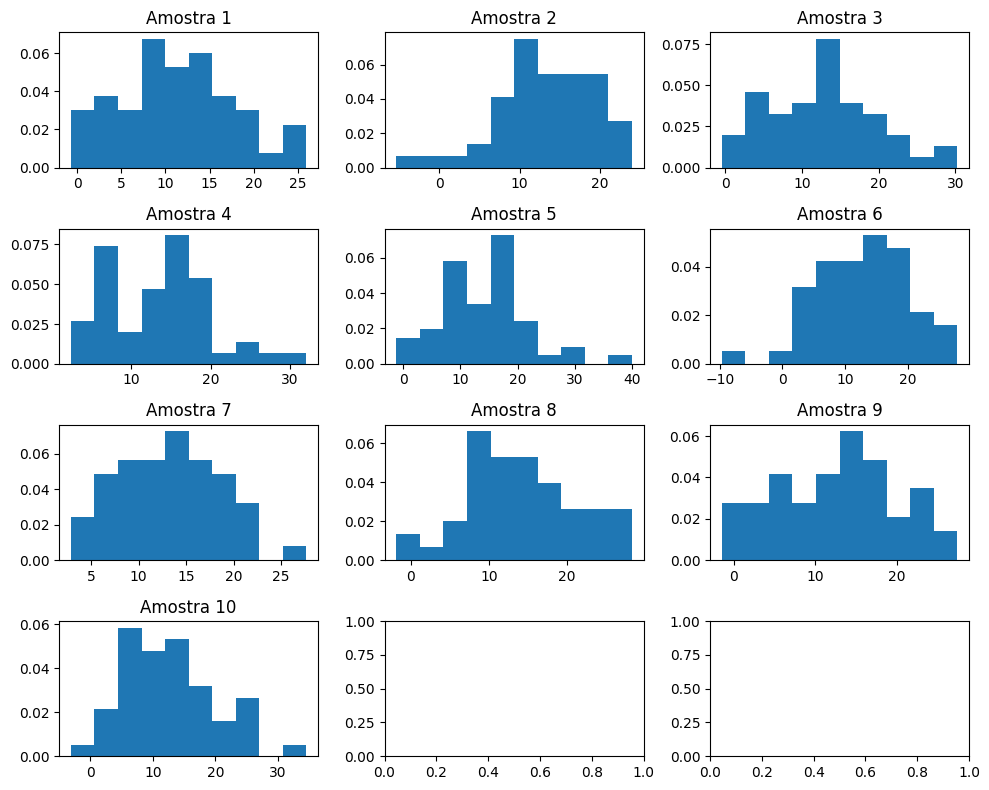

Amostra 1: mu_est = 11.42, sigma2_est = 41.86
Amostra 2: mu_est = 13.12, sigma2_est = 36.71
Amostra 3: mu_est = 12.72, sigma2_est = 49.51
Amostra 4: mu_est = 13.59, sigma2_est = 38.35
Amostra 5: mu_est = 14.06, sigma2_est = 57.26
Amostra 6: mu_est = 12.85, sigma2_est = 56.08
Amostra 7: mu_est = 13.23, sigma2_est = 28.75
Amostra 8: mu_est = 14.27, sigma2_est = 46.54
Amostra 9: mu_est = 12.66, sigma2_est = 55.03
Amostra 10: mu_est = 12.56, sigma2_est = 54.75


In [4]:
n = 50
np.random.seed(42)
amostras = []
for i in range(10):
    x = np.random.normal(13, 7, size=n)
    amostras.append(x)
# Nessa parte eu criei amostras de uma normal(13,7) e armazenei em uma lista vazio de amostras
tabela = pd.DataFrame(amostras).T
tabela.columns = [f"Amostra {i+1}" for i in range(10)]
print(tabela)
fig, axs = plt.subplots(4, 3, figsize=(10, 8))
for i in range(10):
    ax = axs[i // 3, i % 3]
    ax.hist(amostras[i], density=True)
    ax.set_title(f"Amostra {i+1}")
plt.tight_layout()

plt.savefig('hist50.png', dpi=300, bbox_inches='tight')

plt.show()
#plotei todos os histogramas obtidos a das amostras organizando eles lado a lado


mu_estimados = []
sigma2_estimados = []
for i in range(10):
    mu_est = np.mean(amostras[i])
    sigma2_est = np.var(amostras[i]) 
    print(f"Amostra {i+1}: mu_est = {mu_est:.2f}, sigma2_est = {sigma2_est:.2f}")
    mu_estimados.append(mu_est)
    sigma2_estimados.append(sigma2_est)
#Nas proximas seções irei precisar dos mu e sigma estimados para fazer media e algumas outras coisa, por isso guardei eles em listas vazias
# O estimador do Método De Máxima Verossimilhanca para mu é xbarra e para sigma2 é o sigma2 chapéu

In [5]:
mu_estimados = []
sigma2_estimados = []

for i in range(10):
    mu_hat = np.mean(amostras[i])
    sigma2_hat = np.var(amostras[i])    
    mu_estimados.append(mu_hat)
    sigma2_estimados.append(sigma2_hat)

tabela_estimativas = pd.DataFrame({
    'Estimativa de mu': mu_estimados,
    'Estimativa de sigma2': sigma2_estimados
}, index=[f"Amostra {i+1}" for i in range(10)])

print(tabela_estimativas)
#nessa seção usando a biblioteca pandas criei tabelas para organizar as estimativas criadas

            Estimativa de mu  Estimativa de sigma2
Amostra 1          11.421683             41.860830
Amostra 2          13.124466             36.708610
Amostra 3          12.724987             49.511729
Amostra 4          13.587277             38.354684
Amostra 5          14.056785             57.255728
Amostra 6          12.851762             56.081673
Amostra 7          13.225270             28.748809
Amostra 8          14.270492             46.539204
Amostra 9          12.658791             55.027787
Amostra 10         12.557147             54.747331


## média das estimativas

In [6]:
media_das_estimativas_mu = np.mean(mu_estimados)
media_das_estimativas_sigma2 = np.mean(sigma2_estimados)
# usei o mu e o sigma estimados e calculei a média

print(f"Média das estimativas de mu: {media_das_estimativas_mu:.4f}")
print(f"Média das estimativas de sigma2: {media_das_estimativas_sigma2:.4f}")

Média das estimativas de mu: 13.0479
Média das estimativas de sigma2: 46.4836


## Viés Empírico

In [7]:
vies_empirico_mu = media_das_estimativas_mu - 13
vies_empirico_sigma2 = media_das_estimativas_sigma2 - 49
print(vies_empirico_sigma2)
print(vies_empirico_mu)
#calculei o vies empirico para saber o quão proximos da media real eles estão e verificar vício

-2.516361419677324
0.04786596212053418


## Variância Emprica

In [8]:
variancia_mu = (np.sum((mu_estimados - media_das_estimativas_mu)**2))/10
variancia_sigma2 = np.sum((sigma2_estimados - media_das_estimativas_sigma2)**2) / 10
print(variancia_mu)
print(variancia_sigma2)


0.6020401794533554
85.61493267597905


## Erro Quadrático Médio Completo

In [9]:
mu_estimados = np.array(mu_estimados)
sigma2_estimados = np.array(sigma2_estimados) 
EQM_mu = np.mean((mu_estimados - 13)**2)
EQM_sigma = np.mean((sigma2_estimados - 49)**2)

print(EQM_mu)
print(EQM_sigma)
# Eu transformei as duas listas de estimativas em array e calculei o EQM

0.6043313297830797
91.94700747041954


## Verificação Numerica que o EQM = Var + Vies^2

In [10]:
mu_verdadeiro = 13
sigma2_verdadeiro = 49
vies_mu = media_das_estimativas_mu - mu_verdadeiro
vies_sigma2 = media_das_estimativas_sigma2 - sigma2_verdadeiro

eqm_direto_mu = np.sum((mu_estimados - mu_verdadeiro)**2) / 10
eqm_direto_sigma2 = np.sum((sigma2_estimados - sigma2_verdadeiro)**2) / 10


verificacao_mu = variancia_mu + (vies_mu)**2
verificacao_sigma2 = variancia_sigma2 + (vies_sigma2)**2

# Resultados para mu
print(f"--- Parâmetro mu ---")
print(f"EQM calculado diretamente: {eqm_direto_mu:.4f}")
print(f"Variância + Viés^2:        {verificacao_mu:.4f}")

# Resultados para sigma2
print(f" Parâmetro sigma2")
print(f"EQM calculado diretamente: {eqm_direto_sigma2:.6f}")
print(f"Variância + Viés^2:        {verificacao_sigma2:.6f}")

--- Parâmetro mu ---
EQM calculado diretamente: 0.6043
Variância + Viés^2:        0.6043
 Parâmetro sigma2
EQM calculado diretamente: 91.947007
Variância + Viés^2:        91.947007


## D) Compare as médias das estimativas com os respectivos valores verdadeiros dos parâmetros. Comente os resultados obtidos.

In [11]:
print(f"mu estimado: {media_das_estimativas_mu:.2f} | mu verdadeiro: 13")
print(f"sigma2 estimado: {media_das_estimativas_sigma2:.2f} | sigma2 verdadeiro: 49")


mu estimado: 13.05 | mu verdadeiro: 13
sigma2 estimado: 46.48 | sigma2 verdadeiro: 49


Para a média mu o estimador xbarra é não viesado, fazendo assim que ele esteja bem próximo da média real, porém para a variância o estimador é viesado fazendo com que subestime a dipersão verdadeira dos dados

## (e) Os vieses empíricos encontrados permitem concluir que os estimadores são não viesados Justifique.

o viés de mu_estimado é muito próximo de zero isso o que indica que o estimador pra mu é não viesado, porém para a o estimador da variância é viesado, pois deu próximo a -2. 

# Para n = 200

     Amostra 1  Amostra 2  Amostra 3  Amostra 4  Amostra 5  Amostra 6  \
0    13.184623  17.504085   9.083008   7.463963  12.704285  16.334118   
1    14.822252  16.836115   4.954181   3.726865   4.751424  14.095308   
2    10.233981  25.028813   9.517121  21.082164  -1.947342  18.283161   
3    11.569894  22.061916  13.718605  11.614505  12.564196  18.520468   
4     4.098571  13.018984  11.666261  11.737640  13.720912  17.768431   
..         ...        ...        ...        ...        ...        ...   
195  -3.989255  26.467616   1.729153  21.596970   8.362404  14.621117   
196  19.136604  12.249794   9.733674  10.799436   2.658736  21.437759   
197  18.540573   3.288810  13.973932   5.690799  10.639622  17.700292   
198   1.271700  19.401847  18.292777  17.211476   6.997517  21.108404   
199   6.123520  17.556532  10.920008  16.903389   3.433690   2.613912   

     Amostra 7  Amostra 8  Amostra 9  Amostra 10  
0    23.442135   9.780853  11.664594   24.769840  
1    21.424339  24.71

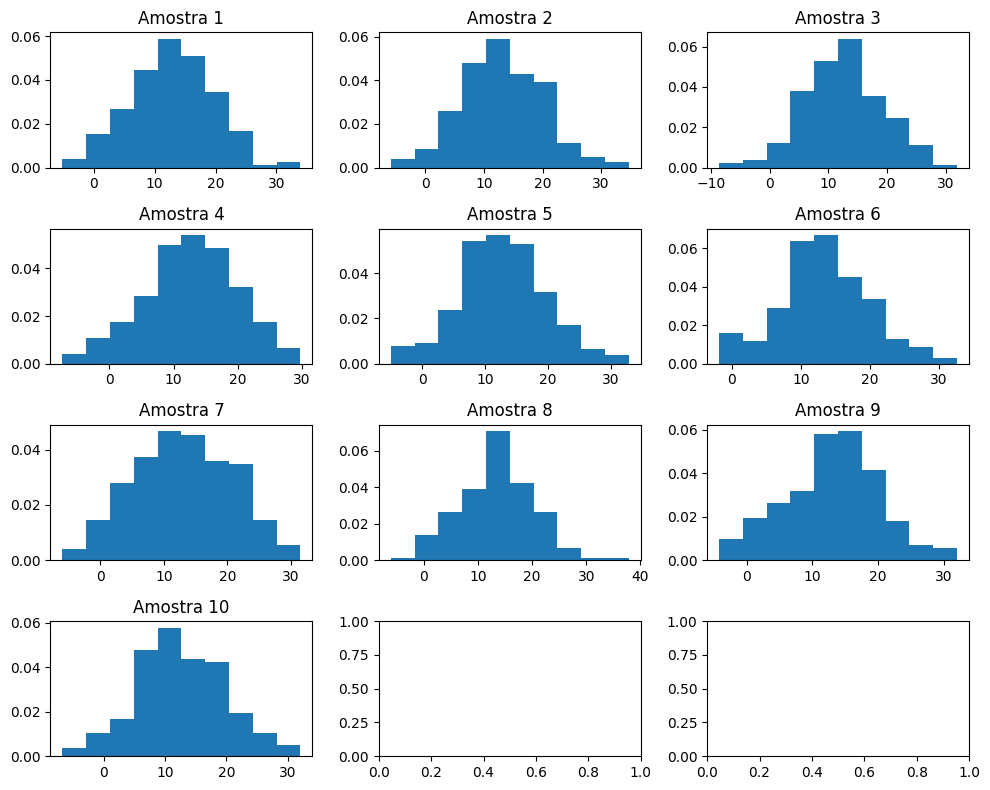

Amostra 1: mu_est = 12.78, sigma2_est = 46.36
Amostra 2: mu_est = 13.12, sigma2_est = 48.27
Amostra 3: mu_est = 12.56, sigma2_est = 44.57
Amostra 4: mu_est = 12.74, sigma2_est = 52.98
Amostra 5: mu_est = 12.74, sigma2_est = 48.05
Amostra 6: mu_est = 13.45, sigma2_est = 43.63
Amostra 7: mu_est = 12.98, sigma2_est = 58.69
Amostra 8: mu_est = 13.55, sigma2_est = 43.17
Amostra 9: mu_est = 12.94, sigma2_est = 51.03
Amostra 10: mu_est = 12.55, sigma2_est = 52.08


In [12]:
N = 200
np.random.seed(45)
amostras200  = []
for i in range(10):
    x = np.random.normal(13, 7, size=N)
    amostras200.append(x)
# Nessa parte eu criei amostras de uma normal(13,7) e armazenei em uma lista vazio de amostras
tabela = pd.DataFrame(amostras200).T
tabela.columns = [f"Amostra {i+1}" for i in range(10)]
print(tabela)
fig, axs = plt.subplots(4, 3, figsize=(10, 8))
for i in range(10):
    ax = axs[i // 3, i % 3]
    ax.hist(amostras200[i], density=True)
    ax.set_title(f"Amostra {i+1}")
plt.tight_layout()

plt.savefig('hist200.png', dpi=300, bbox_inches='tight')

plt.show()
#plotei todos os histogramas obtidos a das amostras organizando eles lado a lado


mu_estimados200 = []
sigma2_estimados200 = []
for i in range(10):
    mu_est200 = np.mean(amostras200[i])
    sigma2_est200 = np.var(amostras200[i]) 
    print(f"Amostra {i+1}: mu_est = {mu_est200:.2f}, sigma2_est = {sigma2_est200:.2f}")
    mu_estimados200.append(mu_est200)
    sigma2_estimados200.append(sigma2_est200)
#Nas proximas seções irei precisar dos mu e sigma estimados para fazer media e algumas outras coisa, por isso guardei eles em listas vazias
# O estimador do Método De Máxima Verossimilhanca para mu é xbarra e para sigma2 é o sigma2 chapéu

In [13]:
mu_estimados200 = []
sigma2_estimados200 = []

for i in range(10):
    mu_hat200 = np.mean(amostras200[i])
    sigma2_hat200 = np.var(amostras200[i])    
    mu_estimados200.append(mu_hat200)
    sigma2_estimados200.append(sigma2_hat200)

tabela_estimativas = pd.DataFrame({
    'Estimativa de mu': mu_estimados200,
    'Estimativa de sigma2': sigma2_estimados200
}, index=[f"Amostra {i+1}" for i in range(10)])

print(tabela_estimativas)
#nessa seção usando a biblioteca pandas criei tabelas para organizar as estimativas criadas

            Estimativa de mu  Estimativa de sigma2
Amostra 1          12.776787             46.360083
Amostra 2          13.123752             48.272368
Amostra 3          12.558634             44.567791
Amostra 4          12.743200             52.977124
Amostra 5          12.737622             48.048472
Amostra 6          13.449714             43.626622
Amostra 7          12.977194             58.694030
Amostra 8          13.549244             43.173026
Amostra 9          12.937181             51.027521
Amostra 10         12.552933             52.078833


## Média Das Estimativas 

In [14]:
media_das_estimativas_mu200 = np.mean(mu_estimados200)
media_das_estimativas_sigma2_200 = np.mean(sigma2_estimados200)
# usei o mu e o sigma estimados e calculei a media

print(f"Média das estimativas de mu: {media_das_estimativas_mu:.4f}")
print(f"Média das estimativas de sigma2: {media_das_estimativas_sigma2_200:.4f}")

Média das estimativas de mu: 13.0479
Média das estimativas de sigma2: 48.8826


## Viés empírico

In [15]:
vies_empirico_mu200 = media_das_estimativas_mu200 - 13
vies_empirico_sigma2_200 = media_das_estimativas_sigma2_200 - 49
print(f'esse é o viés empírico de sigma2: {vies_empirico_sigma2_200}')
print(f'esse é o viés empírico de mu: {vies_empirico_mu200}')

#calculei o vies empirico para saber o quão proximos da media real eles estão e verificar vício

esse é o viés empírico de sigma2: -0.11741308956187879
esse é o viés empírico de mu: -0.05937391627830024


## Variância Empírica

In [16]:
variancia_mu200 = (np.sum((mu_estimados200 - media_das_estimativas_mu200)**2))/10
variancia_sigma2_200 = np.sum((sigma2_estimados200 - media_das_estimativas_sigma2_200)**2) / 10
print(variancia_mu200)
print(variancia_sigma2_200)



0.10677242287381858
21.411925026082105


## EQM Empírico

In [17]:
mu_estimados200 = np.array(mu_estimados200)
sigma2_estimados200 = np.array(sigma2_estimados200) 
EQM_mu200 = np.mean((mu_estimados200 - 13)**2)
EQM_sigma200 = np.mean((sigma2_estimados200 - 49)**2)

print(EQM_mu200)
print(EQM_sigma200)
#eu transformei as duas listas de estimativas em array e calculei o EQM


0.11029768480804122
21.425710859682564


## Comparação dos valores com n = 50 e n = 200

In [18]:
print(" Comparação entre Questão 1 (n=50) e Questão 2 (N=500) ")

print("(i) Proximidade das estimativas médias:")
print(f"n=50  -> Média mu: {media_das_estimativas_mu:.4f} | Média sigma2: {media_das_estimativas_sigma2:.4f}")
print(f"N=500 -> Média mu: {media_das_estimativas_mu200:.4f} | Média sigma2: {media_das_estimativas_sigma2_200:.4f}")
print("Interpretação: Com o aumento da amostra, os valores de N=500 devem aproximar-se ainda mais dos parâmetros verdadeiros (13 e 49).")

print("(ii) Viés empírico:")
print(f"n=50  -> Viés mu: {vies_empirico_mu:.4f} | Viés sigma2: {vies_empirico_sigma2:.4f}")
print(f"N=500 -> Viés mu: {vies_empirico_mu200:.4f} | Viés sigma2: {vies_empirico_sigma2_200:.4f}")
print("Interpretação: O viés de mu mantém-se nulo/residual. O viés de sigma2, que era negativo em n=50, aproxima-se de zero em N=500, mostrando que o estimador é assintoticamente não enviesado.")

print("(iii) Variância empírica:")
print(f"n=50  -> Var mu: {variancia_mu:.4f} | Var sigma2: {variancia_sigma2:.4f}")
print(f"N=500 -> Var mu: {variancia_mu200:.4f} | Var sigma2: {variancia_sigma2_200:.4f}")
print("Interpretação: A variância empírica de N=500 diminui drasticamente face a n=50, indicando que as estimativas se tornam mais precisas e com menor dispersão.")

print("(iv) Erro quadrático médio empírico (EQM):")
print(f"n=50  -> EQM mu: {EQM_mu:.4f} | EQM sigma2: {EQM_sigma:.4f}")
print(f"N=500 -> EQM mu: {EQM_mu200:.4f} | EQM sigma2: {EQM_sigma200:.4f}")
print("Interpretação: A redução substancial da variância e do viés em N=500 resulta num EQM global consideravelmente menor, atestando a consistência dos estimadores.")

 Comparação entre Questão 1 (n=50) e Questão 2 (N=500) 
(i) Proximidade das estimativas médias:
n=50  -> Média mu: 13.0479 | Média sigma2: 46.4836
N=500 -> Média mu: 12.9406 | Média sigma2: 48.8826
Interpretação: Com o aumento da amostra, os valores de N=500 devem aproximar-se ainda mais dos parâmetros verdadeiros (13 e 49).
(ii) Viés empírico:
n=50  -> Viés mu: 0.0479 | Viés sigma2: -2.5164
N=500 -> Viés mu: -0.0594 | Viés sigma2: -0.1174
Interpretação: O viés de mu mantém-se nulo/residual. O viés de sigma2, que era negativo em n=50, aproxima-se de zero em N=500, mostrando que o estimador é assintoticamente não enviesado.
(iii) Variância empírica:
n=50  -> Var mu: 0.6020 | Var sigma2: 85.6149
N=500 -> Var mu: 0.1068 | Var sigma2: 21.4119
Interpretação: A variância empírica de N=500 diminui drasticamente face a n=50, indicando que as estimativas se tornam mais precisas e com menor dispersão.
(iv) Erro quadrático médio empírico (EQM):
n=50  -> EQM mu: 0.6043 | EQM sigma2: 91.9470
N=500 

## Resultados

O aumento do tamanho da amostra (n) aumenta significativamente a precisão dos estimadores de máxima verossimilhança EMV.Com base nos seus resultados numéricos, isso é mostrado pela queda da variância empírica e do Erro Quadrático Médio EQM quando a amostra passou de n=50 para n=200. Estimativas com menor variância mudam muito menos entre diferentes repetições, tornando-se mais precisas.
Teoricamente, este comportamento ilustra a propriedade da consistência dos EMv. À medida que o tamanho da amostra cresce para o infinito, a quantidade de informação sobre a população aumenta, fazendo com que a variância dos estimadores tende a zero e as estimativas convirjam para os verdadeiros parâmetros. O fato de o viés do estimador da variância também ter diminuido com a amostra maior contribui para que tenha melhor precisão e exatidão.